# The App Category That Looks Profitable Because Google Owns It

**Datasets:** 10,841 Google Play apps and 7,197 App Store apps, scraped in 2018 and published on Kaggle.

---

## The recommendation being checked

The brief is to find an app profile that would do well on both the App Store and Google Play, for a company that makes free, ad-supported apps. The conclusion this project usually reaches is to **turn a popular book into an app**, because the books category ranks highly on average installs.

It does rank highly on the average. Here is what the average is made of:

- **Google Play Books**, a Google first-party app preinstalled on Android devices, with 1 billion installs.
- **Amazon Kindle**, **Wattpad**, **Audible**, **Wikipedia** and the **Bible**, each above 100 million.

Google Play Books alone accounts for **60% of every install in the category.** Strip the mean back to a median and the books category falls from 11th of 33 to **25th of 33**.

The recommendation is to enter the one category whose apparent success is owned by Google, Amazon and Wikipedia, and where the typical app does worse than in 24 other categories.

## 1. Loading, and three data problems

In [1]:
%matplotlib inline

import csv
import statistics as stats
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

with open("googleplaystore.csv", encoding="utf8") as f:
    play_rows = list(csv.reader(f))
with open("AppleStore.csv", encoding="utf8") as f:
    store_rows = list(csv.reader(f))

play_header, play = play_rows[0], play_rows[1:]
store_header, store = store_rows[0], store_rows[1:]

print("Google Play: %d apps, %d columns" % (len(play), len(play_header)))
print("App Store:   %d apps, %d columns" % (len(store), len(store_header)))
print()

print("PROBLEM 1: a row with the wrong number of columns")
malformed = [i for i, r in enumerate(play) if len(r) != len(play_header)]
print("  row indices:", malformed)
for i in malformed:
    print("  ", play[i])
print("  Category is missing, so every field after it has shifted left.")
play = [r for i, r in enumerate(play) if i not in malformed]

Google Play: 10841 apps, 13 columns
App Store:   7197 apps, 16 columns

PROBLEM 1: a row with the wrong number of columns
  row indices: [10472]
   ['Life Made WI-Fi Touchscreen Photo Frame', '1.9', '19', '3.0M', '1,000+', 'Free', '0', 'Everyone', '', 'February 11, 2018', '1.0.19', '4.0 and up']
  Category is missing, so every field after it has shifted left.


In [2]:
print("PROBLEM 2: duplicate apps")
name_counts = Counter(r[0] for r in play)
duplicated = [n for n, c in name_counts.items() if c > 1]
print("  app names appearing more than once: %d" % len(duplicated))
print("  redundant rows: %d" % sum(name_counts[n] - 1 for n in duplicated))
print("  worst:", name_counts.most_common(3))
print()

# Keep the row with the most reviews: it is the most recent scrape of that app.
newest = {}
for r in play:
    reviews = int(r[3]) if r[3].isdigit() else 0
    if r[0] not in newest or reviews > newest[r[0]][0]:
        newest[r[0]] = (reviews, r)
play = [v[1] for v in newest.values()]
print("  after deduplication: %d apps" % len(play))
print()

print("PROBLEM 3: Installs is not a number")
install_values = Counter(r[5] for r in play)
print("  distinct values of Installs: %d" % len(install_values))
print("  most common:", [v for v, _ in install_values.most_common(6)])
print()
print("  Google publishes install counts in buckets, so 1,000,000+ covers")
print("  everything from one million to just under five million. Reading it")
print("  as a number means taking the lower bound of each bucket, which can")
print("  understate an app by a factor of five and the whole field is coarse.")

PROBLEM 2: duplicate apps
  app names appearing more than once: 798
  redundant rows: 1181
  worst: [('ROBLOX', 9), ('CBS Sports App - Scores, News, Stats & Watch Live', 8), ('Duolingo: Learn Languages Free', 7)]

  after deduplication: 9659 apps

PROBLEM 3: Installs is not a number
  distinct values of Installs: 21
  most common: ['1,000,000+', '100,000+', '10,000+', '10,000,000+', '1,000+', '100+']

  Google publishes install counts in buckets, so 1,000,000+ covers
  everything from one million to just under five million. Reading it
  as a number means taking the lower bound of each bucket, which can
  understate an app by a factor of five and the whole field is coarse.


**The third problem is the one that limits everything downstream.**

`Installs` has 21 distinct values across 9,659 apps. It is a set of bucket labels, not a measurement. Converting "1,000,000+" to 1000000 takes the lower bound of a bucket that runs up to the next one, so every figure in this notebook is an underestimate of unknown size, and the medians are extremely coarse: a great many categories will tie at exactly 1,000,000 because that is simply the modal bucket.

That coarseness matters for how precisely the results below can be read, and it is stated once here rather than repeated.

## 2. The canonical filters

In [3]:
def mostly_english(name, tolerance=3):
    """Allow a few non-ASCII characters so apps with an emoji in the title
    are not thrown out along with genuinely non-English ones."""
    return sum(1 for c in name if ord(c) > 127) <= tolerance

play_en = [r for r in play if mostly_english(r[0])]
play_free = [r for r in play_en if r[6] == "Free"]
print("Google Play: %d -> %d English -> %d free" % (len(play), len(play_en), len(play_free)))

store_en = [r for r in store if mostly_english(r[1])]
store_free = [r for r in store_en if float(r[4]) == 0]
print("App Store:   %d -> %d English -> %d free" % (len(store), len(store_en), len(store_free)))
print()
print("A caveat on the two outcome columns:")
print("  Google Play gives Installs, a bucketed download count.")
print("  The App Store gives rating_count_tot, the number of ratings left.")
print("  These are different quantities. Only a small fraction of users rate")
print("  an app, so the two cannot be compared directly and are kept separate.")

Google Play: 9659 -> 9614 English -> 8863 free
App Store:   7197 -> 6183 English -> 3222 free

A caveat on the two outcome columns:
  Google Play gives Installs, a bucketed download count.
  The App Store gives rating_count_tot, the number of ratings left.
  These are different quantities. Only a small fraction of users rate
  an app, so the two cannot be compared directly and are kept separate.


## 3. Ranking categories, two ways

In [4]:
def to_installs(text):
    return int(text.replace("+", "").replace(",", ""))

def summarise(groups):
    """For each group: count, mean, median, and what share of the group total
    comes from its single biggest app."""
    out = []
    for name, values in groups.items():
        out.append({"group": name, "n": len(values),
                    "mean": stats.mean(values), "median": stats.median(values),
                    "max": max(values), "top_share": 100 * max(values) / sum(values)})
    return out

play_groups = defaultdict(list)
for r in play_free:
    play_groups[r[1]].append(to_installs(r[5]))
play_stats = summarise(play_groups)

by_mean = sorted(play_stats, key=lambda d: -d["mean"])
by_median = sorted(play_stats, key=lambda d: -d["median"])

print("GOOGLE PLAY, top 10 by MEAN installs (how the usual analysis ranks)")
print("%-22s %5s %13s %11s %10s" % ("category", "n", "mean", "median", "biggest"))
for d in by_mean[:10]:
    print("%-22s %5d %13.0f %11.0f %9.1f%%" %
          (d["group"], d["n"], d["mean"], d["median"], d["top_share"]))

GOOGLE PLAY, top 10 by MEAN installs (how the usual analysis ranks)
category                   n          mean      median    biggest
COMMUNICATION            287      38456119      500000       9.1%
VIDEO_PLAYERS            159      24727872     1000000      25.4%
SOCIAL                   236      23253652      100000      18.2%
PHOTOGRAPHY              261      17840110     1000000      21.5%
PRODUCTIVITY             345      16787331      100000      17.3%
GAME                     862      15588016     1000000       7.4%
TRAVEL_AND_LOCAL         207      13984078      100000      34.5%
ENTERTAINMENT             85      11640706     1000000      10.1%
TOOLS                    750      10801391      100000      12.3%
NEWS_AND_MAGAZINES       248       9549178       50000      42.2%


**Look at the gap between the two middle columns.** Communication averages 38.5 million installs and has a median of 500,000: a factor of **77**. News and Magazines takes **42.2%** of its entire category total from one app; Travel and Local, 34.5%.

These are not categories that perform well. They are categories that contain WhatsApp, YouTube and Google Maps.

## 4. What happens to the books recommendation

In [5]:
books = [d for d in play_stats if d["group"] == "BOOKS_AND_REFERENCE"][0]

print("BOOKS_AND_REFERENCE on Google Play")
print("  apps in category: %d" % books["n"])
print("  mean installs:    %,.0f".replace(",", "") % books["mean"])
print("  median installs:  %.0f" % books["median"])
print("  biggest app is %.1f%% of the whole category" % books["top_share"])
print()
print("  rank by mean:   %d of %d" % (by_mean.index(books) + 1, len(play_stats)))
print("  rank by median: %d of %d" % (by_median.index(books) + 1, len(play_stats)))
print()

book_apps = [r for r in play_free if r[1] == "BOOKS_AND_REFERENCE"]
book_apps.sort(key=lambda r: -to_installs(r[5]))
print("  the apps carrying the average:")
for r in book_apps[:7]:
    print("    %-44s %16s" % (r[0][:44], r[5]))
print()
total = sum(to_installs(r[5]) for r in book_apps)
top6 = sum(to_installs(r[5]) for r in book_apps[:6])
print("  the top 6 of %d apps hold %.1f%% of all installs in the category" %
      (len(book_apps), 100 * top6 / total))

BOOKS_AND_REFERENCE on Google Play
  apps in category: 190
  mean installs:    8767812
  median installs:  50000
  biggest app is 60.0% of the whole category

  rank by mean:   11 of 33
  rank by median: 25 of 33

  the apps carrying the average:
    Google Play Books                              1,000,000,000+
    Wattpad 📖 Free Books                             100,000,000+
    Amazon Kindle                                    100,000,000+
    Bible                                            100,000,000+
    Audiobooks from Audible                          100,000,000+
    Wikipedia                                         10,000,000+
    Cool Reader                                       10,000,000+

  the top 6 of 190 apps hold 84.6% of all installs in the category


In [6]:
print("GOOGLE PLAY, top 10 by MEDIAN installs (a different list)")
print("%-22s %5s %11s %13s" % ("category", "n", "median", "mean"))
for d in by_median[:10]:
    print("%-22s %5d %11.0f %13.0f" % (d["group"], d["n"], d["median"], d["mean"]))
print()
print("Many categories tie at 1,000,000 because that is the modal install")
print("bucket, so this ordering is coarse. The useful information is which")
print("categories are NOT in it, and BOOKS_AND_REFERENCE is one of them.")

GOOGLE PLAY, top 10 by MEDIAN installs (a different list)
category                   n      median          mean
EDUCATION                103     1000000       1833495
ENTERTAINMENT             85     1000000      11640706
GAME                     862     1000000      15588016
VIDEO_PLAYERS            159     1000000      24727872
SHOPPING                 199     1000000       7036877
PHOTOGRAPHY              261     1000000      17840110
WEATHER                   71     1000000       5074486
COMMUNICATION            287      500000      38456119
FOOD_AND_DRINK           110      500000       1924898
HEALTH_AND_FITNESS       273      500000       4188822

Many categories tie at 1,000,000 because that is the modal install
bucket, so this ordering is coarse. The useful information is which
categories are NOT in it, and BOOKS_AND_REFERENCE is one of them.


**The books category ranks 11th of 33 by mean and 25th of 33 by median.**

Google Play Books alone is **60.0%** of all installs in the category, and **the top 6 of 190 apps hold 84.6%** of them. Those six are Google Play Books, Wattpad, Amazon Kindle, the Bible, Audible and Wikipedia.

Two of those are the platform owner and the largest bookseller on earth, shipping preinstalled or near-universal apps backed by content libraries. One is a religious text. One is the free encyclopedia. These are not competitors a new entrant displaces; they are the reason the average looks good.

The median app in this category gets **50,000 installs**, which is worse than in 24 of the other 32 categories.

## 5. The App Store agrees, more starkly

The same check on the other platform. Note the outcome variable differs: the App Store file records the number of ratings, not installs.

In [7]:
store_groups = defaultdict(list)
for r in store_free:
    store_groups[r[11]].append(int(r[5]))
store_stats = summarise(store_groups)

s_by_mean = sorted(store_stats, key=lambda d: -d["mean"])
s_by_median = sorted(store_stats, key=lambda d: -d["median"])

print("APP STORE, top 6 by MEAN ratings")
print("%-20s %5s %11s %10s %10s" % ("genre", "n", "mean", "median", "biggest"))
for d in s_by_mean[:6]:
    print("%-20s %5d %11.0f %10.0f %9.1f%%" %
          (d["group"], d["n"], d["mean"], d["median"], d["top_share"]))
print()
print("APP STORE, top 6 by MEDIAN ratings")
for d in s_by_median[:6]:
    print("%-20s %5d %11.0f %10.0f %9.1f%%" %
          (d["group"], d["n"], d["mean"], d["median"], d["top_share"]))
print()

book_genre = [d for d in store_stats if d["group"] == "Book"][0]
print("Book genre: %d apps, mean %.0f ratings, median %.0f ratings" %
      (book_genre["n"], book_genre["mean"], book_genre["median"]))
print("  rank by mean:   %d of %d" % (s_by_mean.index(book_genre) + 1, len(store_stats)))
print("  rank by median: %d of %d" % (s_by_median.index(book_genre) + 1, len(store_stats)))
print("  biggest app is %.1f%% of the genre" % book_genre["top_share"])

APP STORE, top 6 by MEAN ratings
genre                    n        mean     median    biggest
Navigation               6       86090       8196      66.8%
Reference               18       74942       6614      73.1%
Social Networking      106       71548       4199      39.2%
Music                   66       57327       3850      29.8%
Weather                 28       52280        289      33.9%
Book                    14       39758        422      45.3%

APP STORE, top 6 by MEDIAN ratings
Productivity            56       21028       8738      13.7%
Navigation               6       86090       8196      66.8%
Reference               18       74942       6614      73.1%
Shopping                84       26920       5936      18.5%
Social Networking      106       71548       4199      39.2%
Music                   66       57327       3850      29.8%

Book genre: 14 apps, mean 39758 ratings, median 422 ratings
  rank by mean:   6 of 23
  rank by median: 21 of 23
  biggest app is 45.3% o

**The App Store tells the same story with sharper numbers.**

The Book genre contains **14 free English apps**. It ranks 6th of 23 by mean and **21st of 23 by median**. The median Book app has **422 ratings**.

The top of the mean ranking is worse still as evidence. Navigation ranks first on **six apps**, with 66.8% of the genre's ratings from one of them. Reference ranks second on 18 apps with 73.1% from one. These are not findings about genres; they are single large apps with a label attached.

Both platforms produce the same pattern: the categories that look best on the mean are the ones most completely dominated by one incumbent.

## 6. Charts

Chart 1: 3 figure texts, 0 out of bounds


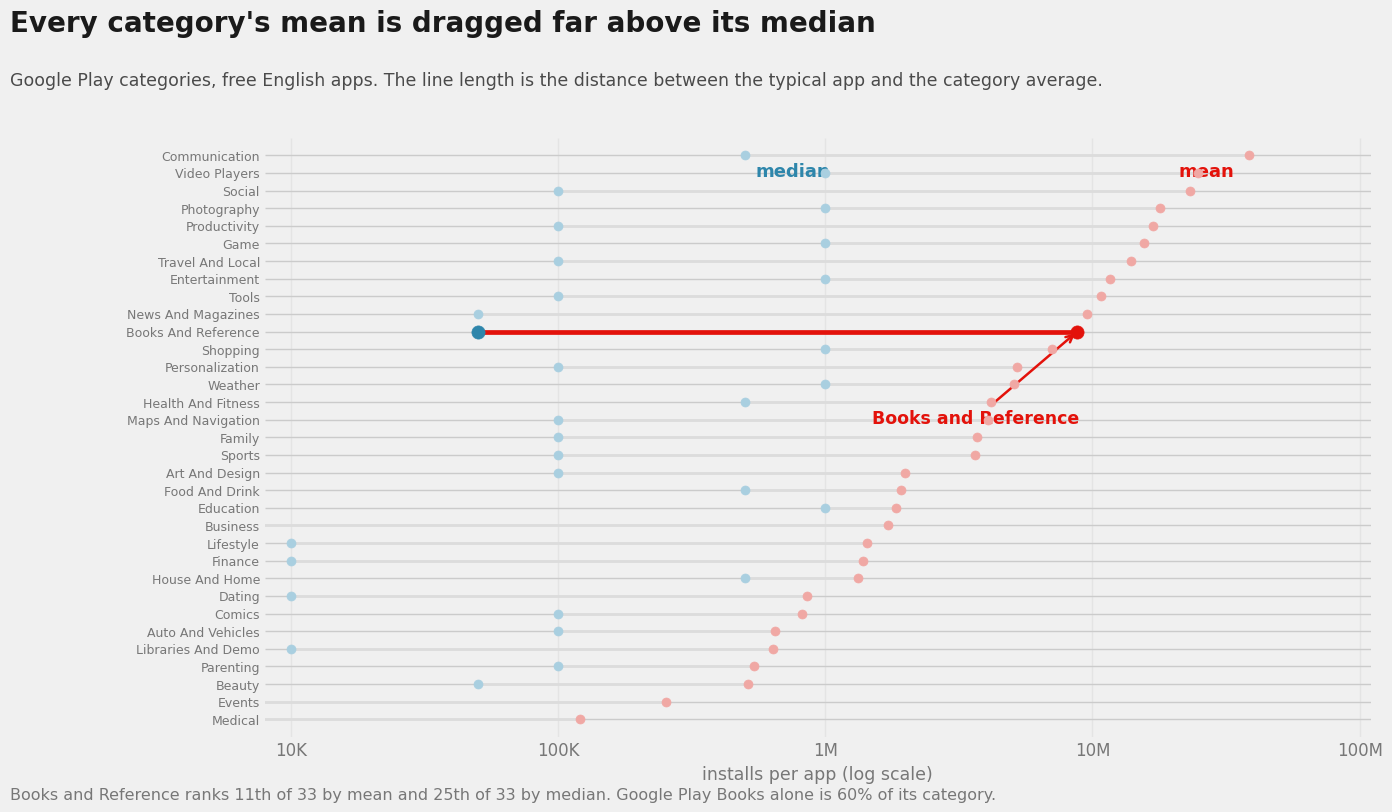

In [8]:
plt.style.use("fivethirtyeight")
C_MEAN = "#e3120b"
C_MED = "#2e86ab"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: mean against median, log scale, books highlighted
fig, ax = plt.subplots(figsize=(14, 8.5))
for d in play_stats:
    is_books = d["group"] == "BOOKS_AND_REFERENCE"
    colour = C_MEAN if is_books else "#b8b8b8"
    ax.plot([d["median"], d["mean"]], [0, 0], alpha=0)

ordered = sorted(play_stats, key=lambda d: d["mean"])
y = np.arange(len(ordered))
for yi, d in zip(y, ordered):
    is_books = d["group"] == "BOOKS_AND_REFERENCE"
    line_colour = C_MEAN if is_books else "#dcdcdc"
    ax.plot([d["median"], d["mean"]], [yi, yi], color=line_colour,
            linewidth=3.4 if is_books else 2, zorder=4 if is_books else 2)
    ax.scatter([d["mean"]], [yi], s=90 if is_books else 42,
               color=C_MEAN if is_books else "#f0a8a4", zorder=5)
    ax.scatter([d["median"]], [yi], s=90 if is_books else 42,
               color=C_MED if is_books else "#a9cfe0", zorder=5)

ax.set_yticks(y)
ax.set_yticklabels([d["group"].replace("_", " ").title() for d in ordered], fontsize=9)
ax.set_xscale("log")
ax.set_xlim(8000, 1.1e8)
ax.set_ylim(-1, len(ordered))
ax.set_xticks([1e4, 1e5, 1e6, 1e7, 1e8])
ax.set_xticklabels(["10K", "100K", "1M", "10M", "100M"], fontsize=12)
ax.set_xlabel("installs per app (log scale)", fontsize=12.5, color="#777777")
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

books_y = [i for i, d in enumerate(ordered) if d["group"] == "BOOKS_AND_REFERENCE"][0]
ax.annotate("Books and Reference", xy=(books["mean"], books_y),
            xytext=(1.5e6, books_y - 5.2), fontsize=12.5, weight="bold", color=C_MEAN,
            arrowprops=dict(arrowstyle="->", color=C_MEAN, linewidth=1.8))
ax.text(2.1e7, len(ordered) - 2.2, "mean", color=C_MEAN, fontsize=13, weight="bold")
ax.text(5.5e5, len(ordered) - 2.2, "median", color=C_MED, fontsize=13, weight="bold")

fig.subplots_adjust(left=0.195, right=0.985, top=0.800, bottom=0.095)
fig.text(0.013, 0.925, "Every category's mean is dragged far above its median",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Google Play categories, free English apps. The line length is the distance between the typical app and the category average.",
         fontsize=12.5, color="#4a4a4a")
fig.text(0.013, 0.022,
         "Books and Reference ranks 11th of 33 by mean and 25th of 33 by median. Google Play Books alone is 60% of its category.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds

all charts within bounds: True


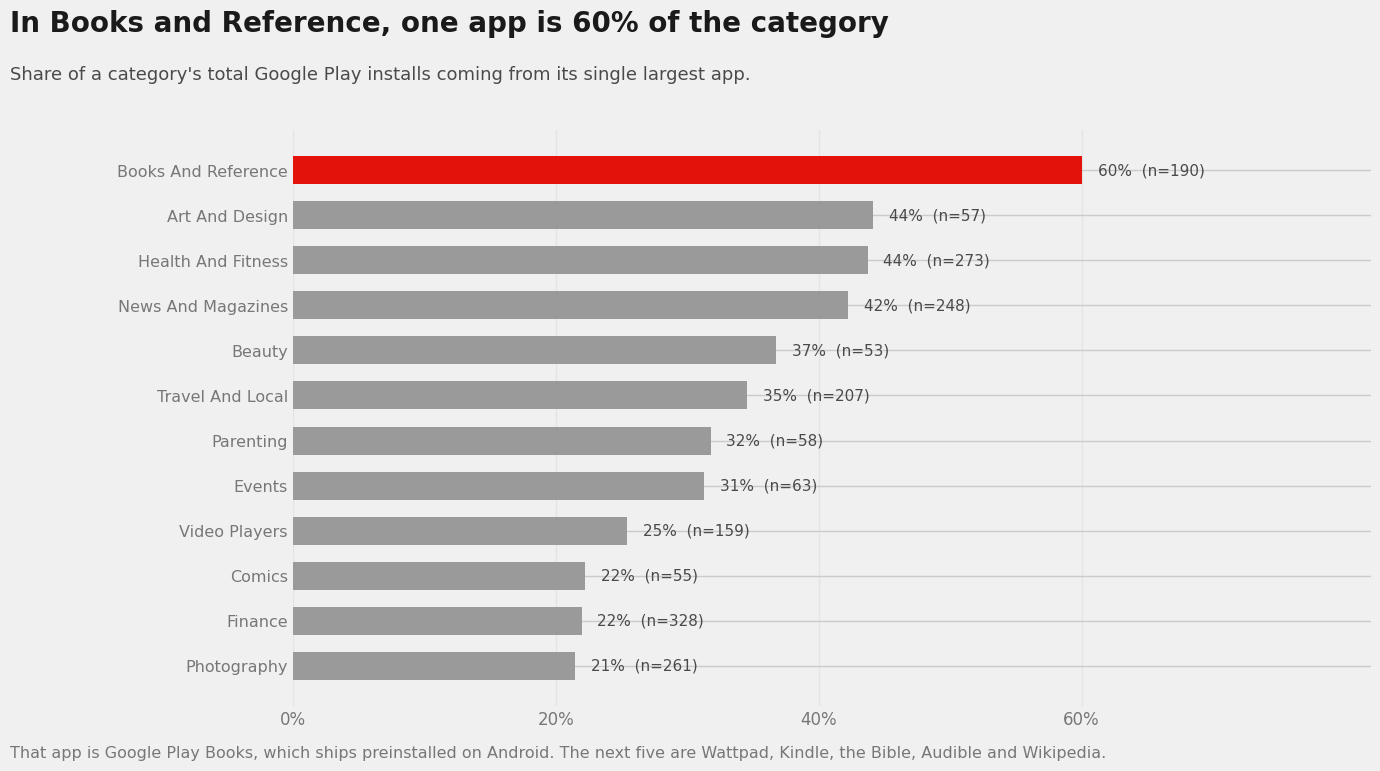

In [9]:
# Chart 2: what one app does to a category
top_share_order = sorted(play_stats, key=lambda d: -d["top_share"])[:12]
y = np.arange(len(top_share_order))
colours = [C_MEAN if d["group"] == "BOOKS_AND_REFERENCE" else "#9a9a9a"
           for d in top_share_order]

fig, ax = plt.subplots(figsize=(14, 8))
ax.barh(y, [d["top_share"] for d in top_share_order], color=colours,
        height=0.62, zorder=3)
ax.invert_yaxis()

for yi, d in zip(y, top_share_order):
    ax.text(d["top_share"] + 1.2, yi, "%.0f%%  (n=%d)" % (d["top_share"], d["n"]),
            va="center", fontsize=11, color="#4a4a4a")

ax.set_yticks(y)
ax.set_yticklabels([d["group"].replace("_", " ").title() for d in top_share_order],
                   fontsize=11.5)
ax.set_xlim(0, 82)
ax.set_xticks([0, 20, 40, 60])
ax.set_xticklabels(["0%", "20%", "40%", "60%"], fontsize=12)
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

fig.subplots_adjust(left=0.215, right=0.985, top=0.805, bottom=0.085)
fig.text(0.013, 0.928, "In Books and Reference, one app is 60% of the category",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.868,
         "Share of a category's total Google Play installs coming from its single largest app.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.020,
         "That app is Google Play Books, which ships preinstalled on Android. The next five are Wattpad, Kindle, the Bible, Audible and Wikipedia.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
print()
print("all charts within bounds:", bool(ok1 and ok2))
plt.show()

## 7. Conclusions

### The books recommendation is backwards

| | Google Play | App Store |
|---|---|---|
| Rank by mean | 11 of 33 | 6 of 23 |
| **Rank by median** | **25 of 33** | **21 of 23** |
| Median outcome | 50,000 installs | 422 ratings |
| Biggest app's share | 60.0% | 45.3% |

The category looks good on the mean and poor on the median, on both platforms independently.

**On Google Play, the top 6 of 190 apps hold 84.6% of all installs in the category.** Those six are Google Play Books (preinstalled on Android), Amazon Kindle, Wattpad, the Bible, Audible and Wikipedia. The platform owner, the largest bookseller on earth, a religious text and the free encyclopedia.

A company shipping a free ad-supported book app is not competing with the median of that category. It is competing for attention in a market where almost nine installs in ten already belong to six incumbents with content libraries it cannot match.

**The App Store makes it starker.** The Book genre has 14 free English apps and a median of **422 ratings**, ranking 21st of 23.

### Why means fail on this data

Every category's mean sits far above its median. Communication averages 38.5 million installs against a median of 500,000, a factor of 77. The categories that top the mean ranking are the ones most completely owned by a single app: News and Magazines takes 42.2% of its total from one app, Travel and Local 34.5%.

On the App Store the same pattern appears with tiny samples: Navigation ranks first on **six apps** with 66.8% of the genre's ratings from one of them, and Reference second on 18 apps with 73.1% from one. These are not genre findings, they are single large apps with a label attached.

**A mean install count answers "how big is the biggest app here?" It does not answer "how would a new app do?", which is the question the brief asks.**

### Three data problems found along the way

1. **One malformed row.** Row 10472 is missing its Category value, so every field after it shifted left, giving an app a rating of 19 on a five-point scale.
2. **1,181 redundant rows.** 798 app names appear more than once; ROBLOX appears nine times. Deduplicated by keeping the row with the most reviews, as the most recent scrape.
3. **Installs is not a number.** It has 21 distinct values across 9,659 apps, because Google publishes buckets. Reading "1,000,000+" as 1000000 takes the lower bound of a bucket running up to the next one, so every figure here understates by an unknown amount and medians are coarse, with many categories tied at exactly 1,000,000.

### What I would not claim

- **Installs are not revenue.** For an ad-supported app what matters is engaged sessions, retention and ad rates, none of which are in this data. A category with modest installs and daily use may beat one with large installs and none.
- **The two platforms measure different things.** Google Play gives bucketed installs; the App Store gives rating counts. Only a small and varying fraction of users rate an app, so the two rankings are computed separately and never combined.
- **The bucketing limits precision throughout.** The median comparison is directionally sound but the exact figures should not be read closely.
- **These are 2018 scrapes,** predating substantial changes to both stores. Nothing here describes the current market.
- **Neither file is the full catalogue.** 10,841 and 7,197 apps are samples of stores holding millions, and nothing states how they were selected, which could bias every category differently.
- **The English filter is a heuristic** that allows up to three non-ASCII characters. It keeps apps with emoji in the title and will still drop some legitimate English apps and admit some non-English ones.
- **Category labels are self-assigned by developers** and inconsistently applied, so the groupings are rough.

### What I would actually recommend

Nothing in this data identifies a profitable app profile, and that is the finding rather than a failure.

What it does support is a negative: **avoid categories where one incumbent holds most of the installs**, because the headline average there is a measure of someone else's moat. By that standard the books category is among the worst choices available, not the best.

A real version of this analysis needs per-app revenue or engagement, the full catalogue rather than a sample, and a measure of how recently entered apps performed. Install counts aggregated by category cannot carry the weight.

---

*Datasets: Google Play Store Apps and Mobile App Store (7200 apps), both scraped in 2018 and published on Kaggle.*